In [1]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP
using LinearAlgebra

[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ Info: Skipping precompilation since __precompile__(false). Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
┌ Warning: Error requiring `Plots` from `LatticeQCD`
│   exception =
│    LoadError: ArgumentError: Package LatticeQCD does not have Plots in its dependencies:
│    - You may have a partially installed environment. Try `Pkg.instantiate()`
│      to ensure all packages in the environment are installed.
│    - Or, if you have LatticeQCD checked out for development and have
│      added Plots as a dependency but haven't updated your primary
│      environment's manifest file, try `Pkg.resolve()`.
│    - Otherwise you may need to report an issue with LatticeQCD
│    Stacktrace:
│      [1] macro expansion
│        @ .\loading.jl:1839 [inlined]
│      [2] macro expansion
│        @ .\lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base .\loading.jl:1816
│      [4] #invoke_in_world#3


In [2]:
NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3
U = Initialize_4DGaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t))

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-0.001719301380445388 - 0.0021807605828687232im -0.001194338847443271 - 0.0012912195459951583im … -0.0029615484782283623 + 0.002461959120083716im 0.000134230244422865 + 0.0008169156804086816im; -0.0037625741938299533 + 0.0016959109730419915im 2.5426270662047557e-5 - 0.0010223434674209734im … 0.00036951047681300925 + 0.0005958322569263704im -0.003016170558004382 + 0.0011259512987009744im; 0.004123359818738562 + 0.0022348301460598597im 0.0026294605836235862 - 0.003642906383293494im … 0.0018775561881586582 + 0.001393546979375777im 0.0008656950263592701 - 0.001356056150176511im;;; -0.0023311698590245396 + 0.0005535612207351768im -0.0009807085290716845 - 0.0005350849131568713im … -0.002232667972839822 + 0.003865223896911283im -0.00178551497811774 - 0.0033287049183114733im; -0.00040654296347773344 + 0.0026972931047538453im -0.0005570531606100261 + 0.0013255679396087733im … -0.003812711265538943 + 0.003237448406362442

In [3]:
P=Onestep()
hop=Hopping_operator(U,P)
W1=Generate_weight(hop)
W2=Generate_weight(hop)

9-element Vector{Spin_matrix}:
 [0.9755150706034786 + 0.0im 0.7755932937696988 + 0.0im -0.6710061733190106 + 0.0im -0.7418393502746612 + 0.0im; 0.5706717872259397 + 0.0im -0.8495922892012828 + 0.0im -0.10873786672309252 + 0.0im 0.9257563851909018 + 0.0im; -0.3146533421325667 + 0.0im 0.6805193163428537 + 0.0im 0.17040753304377412 + 0.0im -0.2750751210613139 + 0.0im; 0.3667972401069486 + 0.0im 1.8087243158084405 + 0.0im 0.36850078073869746 + 0.0im 1.0774388643102315 + 0.0im]
 [-0.13429245965829 + 0.0im -0.11826342547446392 + 0.0im 1.12898988464798 + 0.0im 0.16797327271125975 + 0.0im; -0.8915028910995049 + 0.0im 1.2263524112611937 + 0.0im -0.500081097966201 + 0.0im 1.7714307180238498 + 0.0im; 0.3051157717430471 + 0.0im -0.19991630754606715 + 0.0im -0.687238488992524 + 0.0im -1.2035636321222565 + 0.0im; 0.10290335917582569 + 0.0im 1.5685741654988552 + 0.0im 0.41836948792291245 + 0.0im 0.8924245785415136 + 0.0im]
 [0.7329722975224968 + 0.0im 1.5110161043671728 + 0.0im 1.0833110291867976 + 0

In [4]:
layer1=PTC_Layer(hop,W1)
Norm=NormLayer()
layer2=PTC_Layer(hop,W2)
act=Softmax()
# layer1=Attention_Layer(layer1,sqrt(length(x)) , act,true)
layers=[layer1,Norm,layer2]

3-element Vector{LMP.Layer_types.Layer}:
 PTC_Layer(Spin_matrix[[1.6788208675314442 + 0.0im -0.009580371743122849 + 0.0im -1.648819414954352 + 0.0im 1.6723504116816428 + 0.0im; 0.7623248921687364 + 0.0im -0.6914144385103277 + 0.0im 0.008006541048401159 + 0.0im 2.23895662034977 + 0.0im; -0.7804782645292191 + 0.0im 0.5315669184557875 + 0.0im 0.0729794790993068 + 0.0im -0.34112455131753194 + 0.0im; -0.5547684148029223 + 0.0im -0.33539505937859415 + 0.0im -0.3205878071319409 + 0.0im -0.3031342300675569 + 0.0im], [1.7839299500830241 + 0.0im 0.4210729655076055 + 0.0im -0.931202909461296 + 0.0im -0.5930426847275693 + 0.0im; -0.41385025319808416 + 0.0im 0.5215023841245234 + 0.0im 0.11817620503340408 + 0.0im 1.820852734226066 + 0.0im; -1.1197953516993273 + 0.0im -1.1465710937208962 + 0.0im -0.5052529190295182 + 0.0im 0.8068052549059619 + 0.0im; -0.27636534450891787 + 0.0im -0.7691338671584844 + 0.0im -0.48965521374369314 + 0.0im -1.5863699244987874 + 0.0im], [1.8802216692015812 + 0.0im -0.26726

In [5]:
opt=Adam()
opt.α=0.05

0.05

In [6]:
params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.141139
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 3
params["mass"] = 0.1

D = Dirac_operator(U,x,params)
y=similar(x)
gauss_distribution_fermion!(x)
mul!(y,D,x)
den=norm2(y)
target=x/den
input=y/den

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-4.943487497865333e-6 - 4.789178243723729e-7im -3.7877162661766586e-6 - 2.1275662555580108e-6im … -3.3504912038036372e-6 + 4.605394584785879e-6im -4.576716584344377e-6 - 5.380022861134508e-6im; -3.1183469359697837e-6 - 7.031460144167232e-6im 1.7311145068588083e-6 - 1.1951417486451015e-5im … 1.0890523330703158e-5 - 1.7918553348335807e-6im 1.4695077752458308e-6 - 2.853386460633225e-6im; 7.2318913139909696e-6 + 6.19661520371994e-6im 4.581227611304614e-6 + 9.04689654891888e-6im … 1.0446942386075272e-6 + 3.285411405611004e-6im -2.982561958468437e-6 + 9.583558935710417e-6im;;; 2.160005325930858e-6 + 1.5393445201235575e-7im 2.648914896984669e-6 - 7.57222185116901e-6im … -1.3579170075724481e-5 + 8.510832426257161e-6im -4.2764918588377354e-6 + 7.865390993166649e-7im; -7.744965727612215e-6 - 7.579881400046766e-6im -4.075277737477003e-6 + 4.1762979657783965e-6im … -5.682011620988079e-6 - 9.77315011731586e-7im 1.3170916834

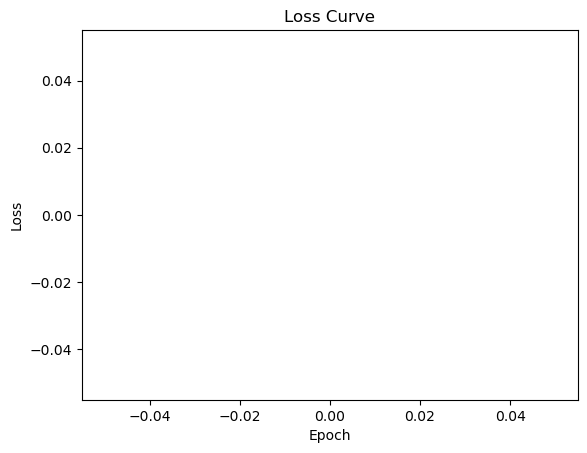

Epoch: 1, Loss: 35.35441571949313 + 0.0im
Epoch: 2, Loss: 33.11248196388194 + 0.0im
Epoch: 3, Loss: 30.628352517107906 + 0.0im
Epoch: 4, Loss: 28.589336015474128 + 0.0im
Epoch: 5, Loss: 26.34485451187584 + 0.0im
Epoch: 6, Loss: 24.119913695087774 + 0.0im
Epoch: 7, Loss: 22.075337622082778 + 0.0im
Epoch: 8, Loss: 20.228423206743166 + 0.0im
Epoch: 9, Loss: 18.3945375243602 + 0.0im
Epoch: 10, Loss: 16.78543507783051 + 0.0im
Epoch: 11, Loss: 15.099021263796653 + 0.0im
Epoch: 12, Loss: 13.709897410343348 + 0.0im
Epoch: 13, Loss: 12.55012864755513 + 0.0im
Epoch: 14, Loss: 11.255964775115169 + 0.0im
Epoch: 15, Loss: 10.198849742908175 + 0.0im
Epoch: 16, Loss: 9.242460753388372 + 0.0im
Epoch: 17, Loss: 8.331146611271473 + 0.0im
Epoch: 18, Loss: 7.555092228123405 + 0.0im
Epoch: 19, Loss: 6.816013467355542 + 0.0im
Epoch: 20, Loss: 6.1857368072315815 + 0.0im
Epoch: 21, Loss: 5.583402819883563 + 0.0im
Epoch: 22, Loss: 5.034658813362945 + 0.0im
Epoch: 23, Loss: 4.560288233045568 + 0.0im
Epoch: 24, 

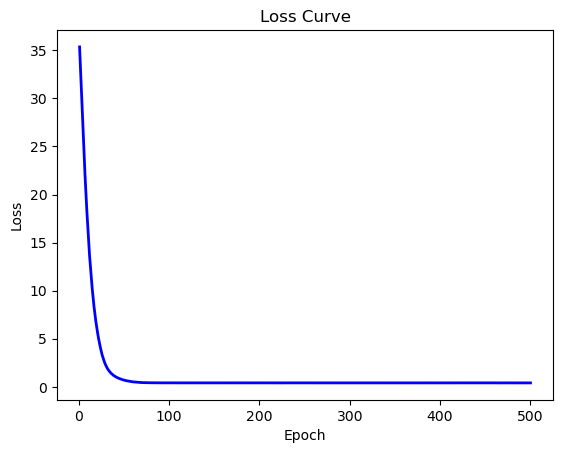

In [7]:
train(opt,layers,x,t,D,epochs=500)